In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
INPUT_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel_with_BH"
)

P_ALPHA = 0.05
FDR_ALPHA = 0.05

In [3]:
available_files = sorted(INPUT_DIR.glob("*10000_*_with_BH.csv"))

print(f"Found {len(available_files)} completed result files:\n")

for path in available_files:
    print(path.name)

Found 13 completed result files:

MI_label_entropy_junker_10000_permutations_with_BH.csv
MI_label_entropy_knoblich_day16_1_10000_permutations_with_BH.csv
MI_label_entropy_knoblich_day16_2_10000_permutations_with_BH.csv
MI_label_entropy_knoblich_day42_1_10000_permutations_with_BH.csv
MI_label_entropy_knoblich_day42_2_10000_permutations_with_BH.csv
MI_label_entropy_morris_atac_10000_permutations_with_BH.csv
MI_label_entropy_morris_rna_10000_permutations_with_BH.csv
MI_label_entropy_treutlein_10000_permutations_with_BH.csv
MI_label_entropy_weinreb_10000_permutations_with_BH.csv
MI_label_entropy_you1_10000_permutations_with_BH.csv
MI_label_entropy_you2_10000_permutations_with_BH.csv
MI_label_entropy_you3_10000_permutations_with_BH.csv
MI_label_entropy_you4_10000_permutations_with_BH.csv


In [4]:
def extract_dataset_name(path):
    """
    Extract the dataset name from filenames such as:
    MI_label_entropy_you2_50_permutations_with_BH.csv
    """
    match = re.match(
        r"MI_label_entropy_(.+)_(\d+)_permutations_with_BH\.csv$",
        path.name,
    )

    if match is None:
        return None

    return match.group(1)

In [5]:
available_datasets = {}

for path in available_files:
    dataset = extract_dataset_name(path)

    if dataset is None:
        print(f"Skipping unrecognized filename: {path.name}")
        continue

    available_datasets[dataset] = path

print("\nDatasets currently available:")
print(sorted(available_datasets))


Datasets currently available:
['junker', 'knoblich_day16_1', 'knoblich_day16_2', 'knoblich_day42_1', 'knoblich_day42_2', 'morris_atac', 'morris_rna', 'treutlein', 'weinreb', 'you1', 'you2', 'you3', 'you4']


In [6]:
data = {}

for dataset, path in sorted(available_datasets.items()):
    try:
        df = pd.read_csv(path)
        data[dataset] = df

        print(
            f"{dataset}: loaded {len(df):,} genes/features "
            f"from {path.name}"
        )

    except Exception as error:
        print(f"Could not load {dataset}: {error}")

junker: loaded 21,062 genes/features from MI_label_entropy_junker_10000_permutations_with_BH.csv
knoblich_day16_1: loaded 29,315 genes/features from MI_label_entropy_knoblich_day16_1_10000_permutations_with_BH.csv
knoblich_day16_2: loaded 28,918 genes/features from MI_label_entropy_knoblich_day16_2_10000_permutations_with_BH.csv
knoblich_day42_1: loaded 28,999 genes/features from MI_label_entropy_knoblich_day42_1_10000_permutations_with_BH.csv
knoblich_day42_2: loaded 29,048 genes/features from MI_label_entropy_knoblich_day42_2_10000_permutations_with_BH.csv
morris_atac: loaded 163,646 genes/features from MI_label_entropy_morris_atac_10000_permutations_with_BH.csv
morris_rna: loaded 13,046 genes/features from MI_label_entropy_morris_rna_10000_permutations_with_BH.csv
treutlein: loaded 20,856 genes/features from MI_label_entropy_treutlein_10000_permutations_with_BH.csv
weinreb: loaded 22,636 genes/features from MI_label_entropy_weinreb_10000_permutations_with_BH.csv
you1: loaded 25,349 

In [7]:
required_columns = {
    "gene",
    "true_mi",
    "empirical_p_value",
    "bh_adjusted_p_value",
    "significant_percentile_95",
    "significant_uncorrected_p_0.05",
    "significant_BH_FDR_0.05",
}

valid_data = {}

for dataset, df in data.items():
    missing = required_columns.difference(df.columns)

    if missing:
        print(
            f"{dataset}: skipped because columns are missing: "
            f"{sorted(missing)}"
        )
        continue

    if len(df) == 0:
        print(f"{dataset}: skipped because the file is empty")
        continue

    valid_data[dataset] = df
    print(f"{dataset}: ready for analysis")

junker: ready for analysis
knoblich_day16_1: ready for analysis
knoblich_day16_2: ready for analysis
knoblich_day42_1: ready for analysis
knoblich_day42_2: ready for analysis
morris_atac: ready for analysis
morris_rna: ready for analysis
treutlein: ready for analysis
weinreb: ready for analysis
you1: ready for analysis
you2: ready for analysis
you3: ready for analysis
you4: ready for analysis


In [8]:
summary_rows = []

for dataset, df in valid_data.items():
    valid = df[
        np.isfinite(df["true_mi"])
        & np.isfinite(df["empirical_p_value"])
        & np.isfinite(df["bh_adjusted_p_value"])
    ].copy()

    percentile_sig = valid["significant_percentile_95"].astype(bool)
    uncorrected_sig = valid[
        "significant_uncorrected_p_0.05"
    ].astype(bool)
    bh_sig = valid[
        "significant_BH_FDR_0.05"
    ].astype(bool)

    n_total = len(valid)
    n_percentile = int(percentile_sig.sum())
    n_uncorrected = int(uncorrected_sig.sum())
    n_bh = int(bh_sig.sum())

    lost_after_bh = uncorrected_sig & ~bh_sig

    summary_rows.append(
        {
            "dataset": dataset,
            "n_tested": n_total,
            "percent_uncorrected_significant": (
                100 * n_uncorrected / n_total
                if n_total > 0 else np.nan
            ),

            "percent_BH_significant": (
                100 * n_bh / n_total
                if n_total > 0 else np.nan
            ),
        }
    )

summary_df = pd.DataFrame(summary_rows).sort_values("dataset")
summary_df.round(3)

,dataset,n_tested,percent_uncorrected_significant,percent_BH_significant
0,junker,21062,10.963,2.440
1,knoblich_day16_1,29315,8.699,1.845
2,knoblich_day16_2,28904,7.234,1.432
3,knoblich_day42_1,28999,8.362,1.448
4,knoblich_day42_2,29048,20.246,7.057
5,morris_atac,163646,7.117,0.000
6,morris_rna,13046,18.994,2.690
7,treutlein,20856,61.901,59.081
8,weinreb,22636,38.196,33.495
9,you1,25349,55.852,51.043


In [9]:
check_rows = []

for dataset, df in valid_data.items():
    n_total = len(df)

    n_zero = int(
        (df["n_perm_ge_true_mi"] == 0).sum()
    )

    n_one = int(
        (df["n_perm_ge_true_mi"] == 1).sum()
    )

    n_bh = int(
        df["significant_BH_FDR_0.05"].sum()
    )

    check_rows.append(
        {
            "dataset": dataset,
            "n_total": n_total,
            "n_zero_exceedances": n_zero,
            "percent_zero_exceedances": 100 * n_zero / n_total,
            "n_one_exceedance": n_one,
            "n_BH_significant": n_bh,
        }
    )

pd.DataFrame(check_rows).round(3)

,dataset,n_total,n_zero_exceedances,percent_zero_exceedances,n_one_exceedance,n_BH_significant
0,junker,21062,216,1.026,66,514
1,knoblich_day16_1,29315,329,1.122,55,541
2,knoblich_day16_2,28918,270,0.934,44,414
3,knoblich_day42_1,28999,270,0.931,44,420
4,knoblich_day42_2,29048,733,2.523,165,2050
5,morris_atac,163646,28,0.017,26,0
6,morris_rna,13046,128,0.981,36,351
7,treutlein,20856,8795,42.170,372,12322
8,weinreb,22636,5461,24.125,221,7582
9,you1,25349,8624,34.021,397,12939


In [12]:
mean_true_mi_dict = {
    dataset: df["true_mi"].mean()
    for dataset, df in valid_data.items()
}

summary_df["mean_true_mi"] = summary_df["dataset"].map(mean_true_mi_dict)

In [20]:
summary_df = summary_df[
    ~summary_df["dataset"].isin(["morris_rna", "morris_atac"])
].copy()

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr


def plot_BH_sign_genes_vs_mean_mi(summary_df):
    """
    Plots percentage of BH-significant genes vs mean true MI across all genes,
    using the old dataset colors and a red dashed linear fit.

    Parameters
    ----------
    summary_df : pd.DataFrame
        Must contain:
        - 'dataset'
        - 'percent_BH_significant'
        - 'mean_true_mi'
    """

    # Old color scheme mapped to current dataset names
    color_dict = {
        "junker": "#C4A12E",           # ZFL
        "knoblich_day16_1": "#7EA52B", # HBO2_16_1
        "knoblich_day16_2": "#37B55B", # HBO2_16_2
        "knoblich_day42_1": "#34B38A", # HBO2_42_1
        "knoblich_day42_2": "#48B8C7", # HBO2_42_2
        "you1": "#3FA0D8",             # HBO3_1
        "you2": "#8E8FF0",             # HBO3_2
        "you3": "#C66AE8",             # HBO3_3
        "you4": "#E76BCB",             # HBO3_4
        "weinreb": "#F06C7F",          # MHSPC
        "treutlein": "#D9842B",        # HBO1
    }

    # Keep only rows with valid values
    plot_df = summary_df[
        ["dataset", "percent_BH_significant", "mean_true_mi"]
    ].dropna().copy()

    plt.figure(figsize=(7, 5))

    # Scatter plot with fixed colors
    sns.scatterplot(
        data=plot_df,
        x="percent_BH_significant",
        y="mean_true_mi",
        hue="dataset",
        palette=color_dict,
        s=80
    )

    # Pearson correlation
    r, pval = pearsonr(
        plot_df["percent_BH_significant"],
        plot_df["mean_true_mi"]
    )

    print(f"Pearson r = {r:.4f}")
    print(f"p-value = {pval:.4e}")

    # Linear fit
    x_vals = np.linspace(
        plot_df["percent_BH_significant"].min(),
        plot_df["percent_BH_significant"].max(),
        100
    )

    fit = np.polyfit(
        plot_df["percent_BH_significant"],
        plot_df["mean_true_mi"],
        1
    )

    y_vals = np.poly1d(fit)(x_vals)

    # Red dashed line like old plot
    plt.plot(
        x_vals,
        y_vals,
        color="red",
        linestyle="--",
        linewidth=2,
        label="linear fit"
    )

    # Pearson text
    plt.text(
        0.05,
        0.95,
        f"Pearson r = {r:.3f}\np = {pval:.3e}",
        transform=plt.gca().transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", alpha=0.3)
    )

    plt.xlabel("Percentage of BH-significant genes")
    plt.ylabel("Mean mutual information")
    plt.title("BH-significant genes vs mean mutual information")

    plt.tight_layout()

    plt.savefig(
        "/fast/AG_Metzger/philipp/python_files/gene_signature/"
        "mutual_information_approach/November_25_ReDo/"
        "figures/BH_sign_percentage_vs_mean_true_mi.pdf",
        bbox_inches="tight"
    )

    plt.show()

Pearson r = 0.7447
p-value = 8.5580e-03


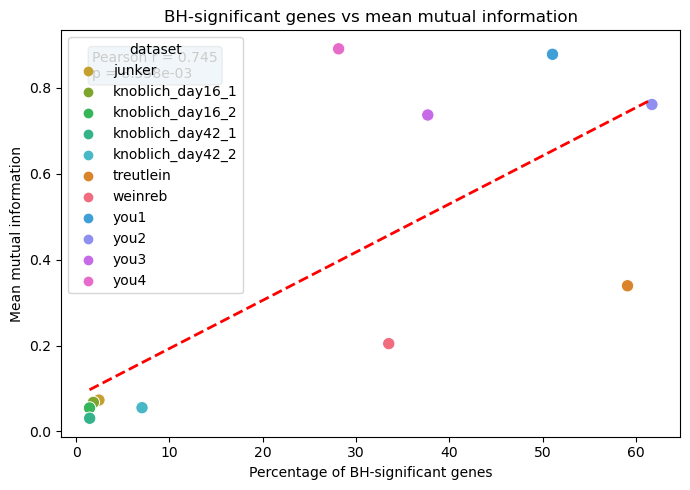

In [21]:
plot_BH_sign_genes_vs_mean_mi(summary_df)